In [1]:
#!pip install mlflow

# ML Ops

Load Data, Train and Compare Models

# Imports

In [1]:
import mlflow
import mlflow.sklearn

import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.model_selection import learning_curve

import matplotlib.pyplot as plt
import numpy as np

### Model Hyperparameter Configuration

In [3]:
# Set random seeds for reproducibility
torch.manual_seed(NN_RANDOM_STATE)
np.random.seed(NN_RANDOM_STATE)

NameError: name 'torch' is not defined

### Connecting to GCS

In [5]:
# --- GCP Configuration ---
PROJECT_ID = "healthy-air-analysis"
BUCKET_NAME = "uci_air_quality_20119102"

In [7]:
# Google Cloud Storage Configuration
# ---------------------------------------------------------------------
PROJECT_ID = "healthy-air-analysis"
BUCKET_NAME = "uci_air_quality_20119102"
LOCATION = "EU"

print(f"Project: {PROJECT_ID}")
print(f"Bucket: gs://{BUCKET_NAME}")

# Load the dataset splits from GCS processed/v1 folder
train_url = f"gs://{BUCKET_NAME}/processed/v1/train.parquet"
eval_url = f"gs://{BUCKET_NAME}/processed/v1/evaluation.parquet"
test_url = f"gs://{BUCKET_NAME}/processed/v1/test.parquet"

# Reading the files using pandas
df_train = pd.read_parquet(train_url)
df_eval = pd.read_parquet(eval_url)
df_test = pd.read_parquet(test_url)

print(f"Loaded train shape: {df_train.shape}, dev shape: {df_eval.shape}, test shape: {df_test.shape}")
df_train.head()

Project: healthy-air-analysis
Bucket: gs://uci_air_quality_20119102
Loaded train shape: (5398, 20), dev shape: (1156, 20), test shape: (1158, 20)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16,Datetime,Target_Next_Hour,Target_Datetime
0,3/10/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN,2004-03-10 18:00:00,GOOD,2004-03-10 19:00:00
1,3/10/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN,2004-03-10 19:00:00,MODERATE,2004-03-10 20:00:00
2,3/10/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN,2004-03-10 20:00:00,MODERATE,2004-03-10 21:00:00
3,3/10/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN,2004-03-10 21:00:00,MODERATE,2004-03-10 22:00:00
4,3/10/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN,2004-03-10 22:00:00,GOOD,2004-03-10 23:00:00


## Target and Features

In [3]:
target = "Target_Next_Hour"

features = [
    "NO2(GT)",
    "PT08.S4(NO2)",
    "T",
    "RH",
    "AH"
]

X_train = train_df[features]
y_train = train_df[target]

X_eval = eval_df[features]
y_eval = eval_df[target]

In [ ]:
#Feature Normalization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### AI training

In [ ]:
# Define PyTorch MLP Model Architecture
class TitanicMLP(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(TitanicMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.Sigmoid(),
            nn.Linear(hidden_size, hidden_size),
            nn.Sigmoid(),
            nn.Linear(hidden_size, hidden_size),
            nn.Sigmoid(),
            nn.Linear(hidden_size, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

In [4]:
for n_trees in [50, 100, 200]:

    with mlflow.start_run():

        model = RandomForestClassifier(
            n_estimators=n_trees,
            random_state=42
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_eval)

        accuracy = accuracy_score(
            y_eval,
            predictions
        )

        mlflow.log_param(
            "n_estimators",
            n_trees
        )

        mlflow.log_metric(
            "accuracy",
            accuracy
        )

        mlflow.sklearn.log_model(
            model,
            "model"
        )

        print(
            f"Trees={n_trees}, Accuracy={accuracy:.3f}"
        )

2026/11/19 23:37:23 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


MlflowException: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['sklearn.tree._tree.Tree'].

- sklearn.tree._tree.Tree: sklearn.tree._tree.Tree (the shared node storage for DecisionTree*, RandomForest*, ExtraTrees*, and GradientBoosting* models) stores raw node indices (left_child, right_child, feature) that scikit-learn indexes into without bounds checking. A malicious file can set these to out-of-range values: skops loads the object successfully, but calling .predict() on it can then crash the process (segfault) or read out-of-bounds memory. If you created the file yourself or otherwise fully trust its source, you can load it with trusted=["sklearn.tree._tree.Tree"].

Only add the specific types you have reviewed and trust to the `trusted` argument; avoid passing everything repo

In [5]:
train_sizes, train_scores, val_scores = (
    learning_curve(
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
        train_sizes=np.linspace(
            0.1,
            1.0,
            10
        )
    )
)

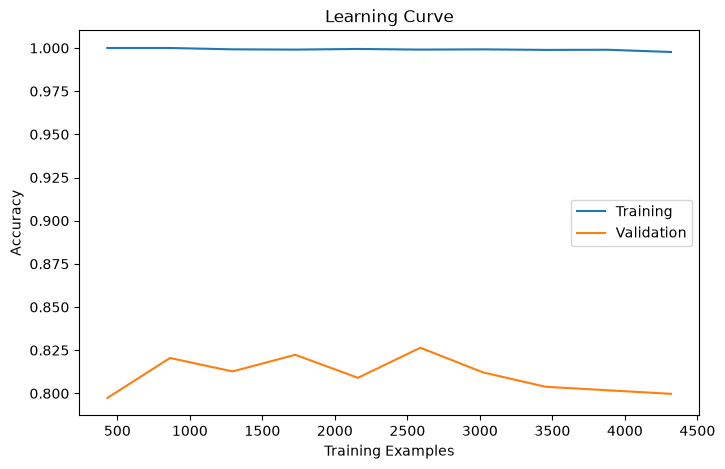

In [6]:
plt.figure(figsize=(8,5))

plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    label="Training"
)

plt.plot(
    train_sizes,
    val_scores.mean(axis=1),
    label="Validation"
)

plt.xlabel("Training Examples")
plt.ylabel("Accuracy")
plt.title("Learning Curve")
plt.legend()

plt.savefig(
    "../reports/learning_curve.png"
)

plt.show()
